# 02. Data Cleaning and Exploratory Data Analysis

**Objective:** retain collision records with usable coordinates, audit the original cleaning steps, and examine temporal counts and spatial patterns before grid assignment.


## 1. Load and audit data

Load the Manhattan collision extract and inspect its schema, a sample of records, and coordinate ranges.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/manhattan_collisions.csv")

display(df.head())
df.info()
display(df.describe())


,collision_id,crash_date,crash_time,borough,latitude,longitude,on_street_name
0,000008347c2c9ef23a99545a0a815898,2023-08-25T00:00:00.000,19:56,MANHATTAN,40.709354,-74.00816,NaN
1,0000a5c3f314ea75418497e73c018fe1,2020-01-18T00:00:00.000,13:30,MANHATTAN,40.753242,-73.96662,1 AVENUE
2,0001ac4d9de42ec118e73c0358c0487b,2024-04-27T00:00:00.000,22:07,MANHATTAN,40.784590,-73.94198,EAST 99 STREET
3,0001ffa7292a1d4d324b9d74ee7c2d25,2023-04-04T00:00:00.000,23:00,MANHATTAN,40.724003,-73.99102,NaN
4,0002965ce22b53380166aad83371220a,2020-07-11T00:00:00.000,17:11,MANHATTAN,40.779602,-73.95553,NaN


<class 'pandas.DataFrame'>
RangeIndex: 99102 entries, 0 to 99101
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   collision_id    99102 non-null  str    
 1   crash_date      99102 non-null  str    
 2   crash_time      99102 non-null  str    
 3   borough         99102 non-null  str    
 4   latitude        96368 non-null  float64
 5   longitude       96368 non-null  float64
 6   on_street_name  61403 non-null  str    
dtypes: float64(2), str(5)
memory usage: 12.5 MB


,latitude,longitude
count,96368.000000,96368.000000
mean,40.333238,-73.182028
std,4.190415,7.602935
min,0.000000,-74.017980
25%,40.737986,-73.991650
50%,40.760600,-73.976630
75%,40.797737,-73.948698
max,40.873020,0.000000


## 2. Data cleaning

### 2.1. Correct data types

Convert dates with invalid values coerced to missing and longitude to `float64`. Latitude keeps the numeric type inferred when reading the source CSV.


In [2]:
df_clean = df.copy()

# Preserve the original type conversions.
df_clean["crash_date"] = pd.to_datetime(
    df_clean["crash_date"], errors="coerce"
)
df_clean["longitude"] = df["longitude"].astype("float64")


### 2.2. Handle missing coordinates

Inspect missingness, then remove rows missing latitude or longitude. Missing street names are retained because spatial assignment uses coordinates.


In [3]:
missing_df = pd.DataFrame({
    "Missing count": df_clean.isna().sum(),
    "Missing (%)": (
        df_clean.isna().sum() / len(df_clean) * 100
    ).round(2)
})
display(
    missing_df[missing_df["Missing count"] > 0]
    .sort_values("Missing (%)", ascending=False)
)

data_count = len(df)
df_clean = df_clean.dropna(axis=0, subset=["latitude", "longitude"])
clean_count_missing = len(df_clean)


,Missing count,Missing (%)
on_street_name,37699,38.04
latitude,2734,2.76
longitude,2734,2.76


### 2.3. Check duplicate collision IDs

Report duplicate identifiers without adding a new removal step.


In [4]:
print("Duplicate collision IDs:", df_clean["collision_id"].duplicated().sum())


Duplicate collision IDs: 0


### 2.4. Check coordinate bounds

Apply the original broad coordinate bounds: latitude 40.49–41.00° and longitude −74.27–−73.68°. The exact Manhattan boundary filter is applied in Notebook 03.


In [5]:
lat_min, lat_max, lon_min, lon_max = 40.49, 41.00, -74.27, -73.68

df_clean = df_clean[
    (df_clean["longitude"] <= lon_max) &
    (df_clean["longitude"] >= lon_min) &
    (df_clean["latitude"] <= lat_max) &
    (df_clean["latitude"] >= lat_min)
]
clean_count_coord_fix = len(df_clean)


### 2.5. Review and save the cleaned records

Review the number of rows removed at each cleaning stage. Preserve both original output files, including the indexed copy.


In [6]:
cleaning_summary = pd.DataFrame({
    "Stage": ["Original records", "After missing-coordinate removal", "After coordinate bounds"],
    "Records retained": [data_count, clean_count_missing, clean_count_coord_fix],
    "Records removed at stage": [
        0,
        data_count - clean_count_missing,
        clean_count_missing - clean_count_coord_fix
    ]
})
display(cleaning_summary)
print(f"Retention rate: {clean_count_coord_fix / data_count * 100:.2f}%")


,Stage,Records retained,Records removed at stage
0,Original records,99102,0
1,After missing-coordinate removal,96368,2734
2,After coordinate bounds,95339,1029


Retention rate: 96.20%


Cleaning retains 95,338 of 99,101 records (96.20%). Missing coordinates account for 2,734 removals, and the coordinate bounds remove a further 1,029 records. No duplicate collision IDs were found.


In [7]:
filepath = Path("../data/processed/manhattan_collision_cleaned.csv")
filepath.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv("../data/processed/manhattan_collision_cleaned.csv", index=False)
df_clean.to_csv("../data/processed/manhattan_collision_cleaned_indexed.csv", index=True)


## 3. Temporal patterns

Aggregate cleaned records by calendar quarter and year, keeping the observations in chronological order.


In [8]:
df_eda = df_clean.copy()
quarterly_count = (
    df_eda["crash_date"].dt.to_period("Q")
    .value_counts().sort_index()
)
yearly_count = (
    df_eda["crash_date"].dt.to_period("Y")
    .value_counts().sort_index()
)

print("Observed quarters, 2019–2025:", len(quarterly_count))


Observed quarters, 2019–2025: 28


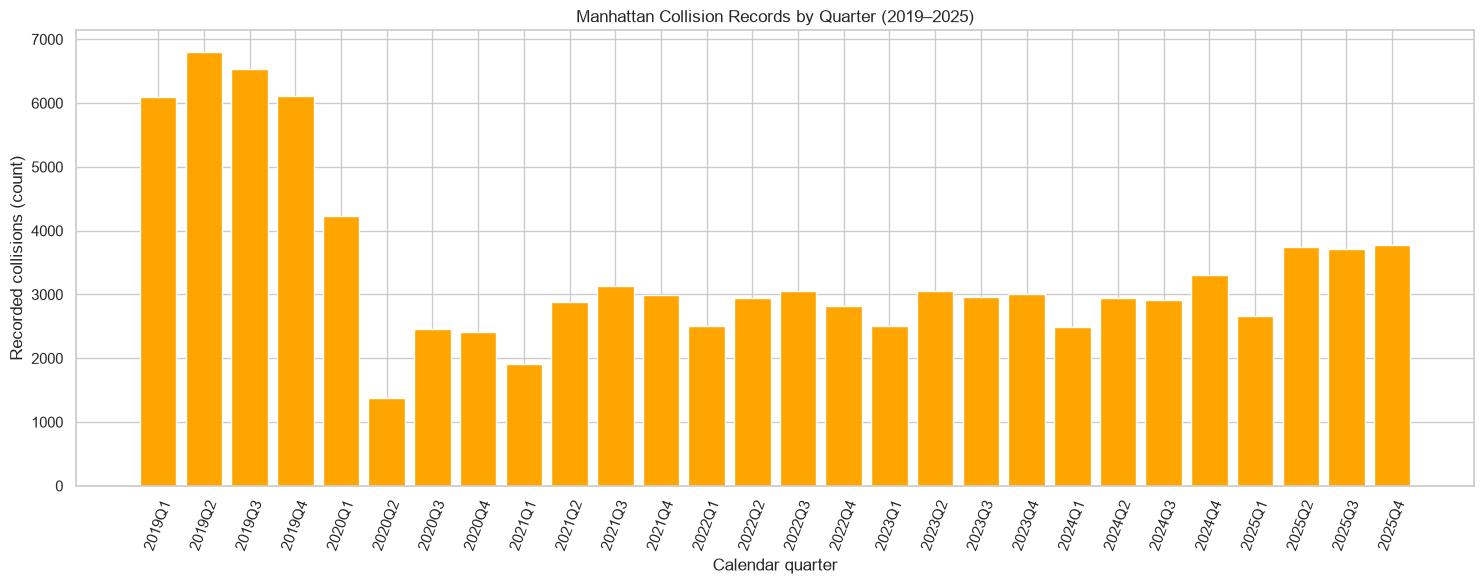

In [9]:
x = range(len(quarterly_count))
plt.figure(figsize=(15, 6))
plt.bar(x, quarterly_count.values, color="orange")
plt.xticks(
    ticks=list(x),
    labels=quarterly_count.index.astype(str),
    rotation=70
)
plt.title("Manhattan Collision Records by Quarter (2019–2025)")
plt.xlabel("Calendar quarter")
plt.ylabel("Recorded collisions (count)")
plt.tight_layout()
plt.show()


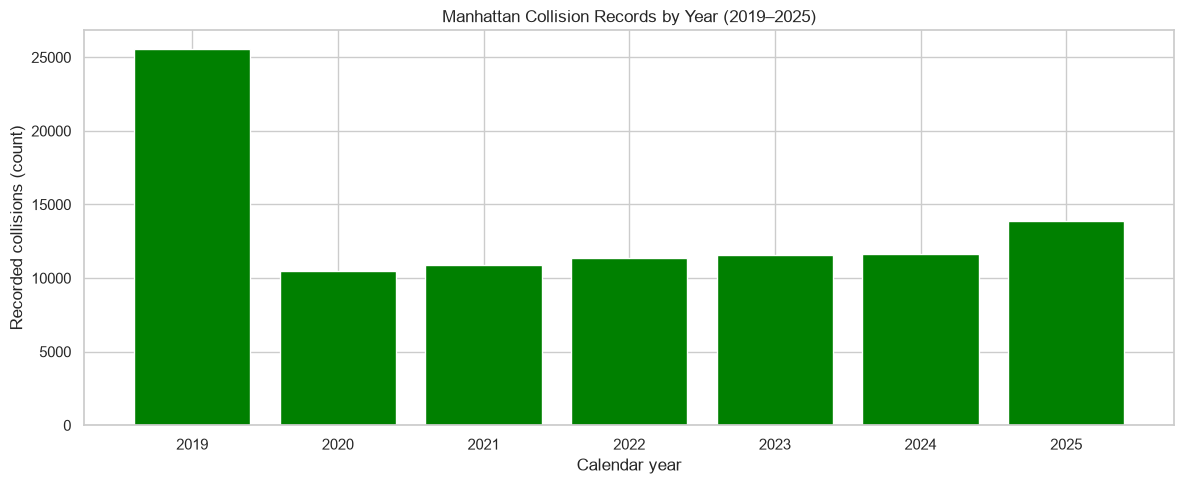

In [10]:
x = range(len(yearly_count))
plt.figure(figsize=(12, 5))
plt.bar(x, yearly_count.values, color="green")
plt.xticks(ticks=list(x), labels=yearly_count.index.astype(str))
plt.title("Manhattan Collision Records by Year (2019–2025)")
plt.xlabel("Calendar year")
plt.ylabel("Recorded collisions (count)")
plt.tight_layout()
plt.show()


Annual recorded collisions fall from 25,547 in 2019 to 10,468 in 2020, then rise each year to 13,889 in 2025. These counts describe the retained records; they do not establish the causes of the changes.


## 4. Collision distributions

Summarize total collision counts across the 28 observed quarters.


In [11]:
display(quarterly_count.describe().rename("Quarterly collision count"))
print("Quarters with zero recorded collisions:", quarterly_count.eq(0).sum())


count      28.000000
mean     3404.964286
std      1364.570519
min      1379.000000
25%      2629.750000
50%      2978.500000
75%      3714.500000
max      6799.000000
Name: Quarterly collision count, dtype: float64

Quarters with zero recorded collisions: 0


Quarterly totals range from 1,379 to 6,799, with a median of 2,978.5 records. Every observed quarter contains collisions. This describes borough-level quarterly totals; grid-cell counts are constructed in Notebook 03.


## 5. Spatial patterns

Inspect all retained collision coordinates before the exact borough boundary and grid assignment steps.


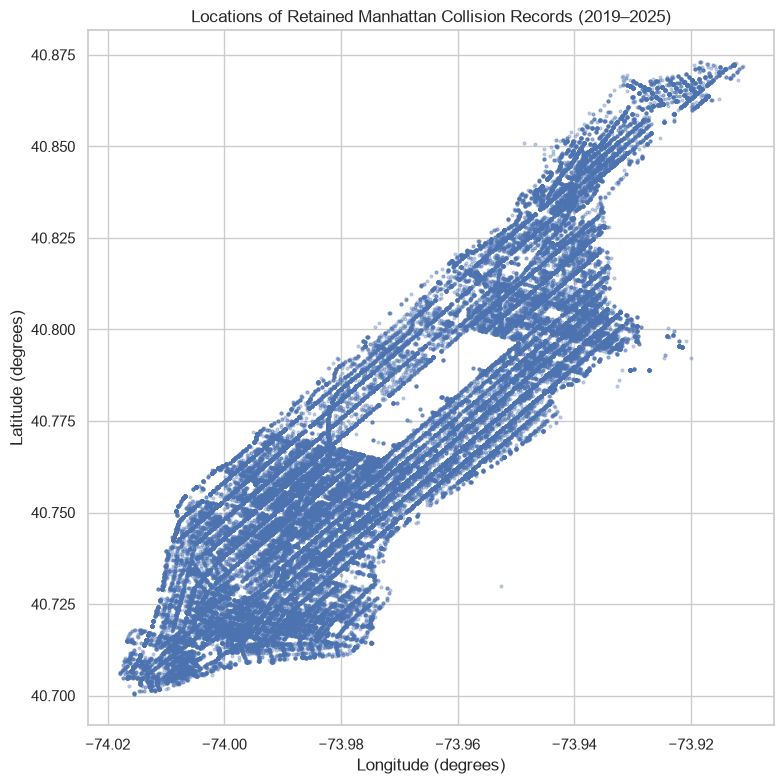

In [12]:
plt.figure(figsize=(8, 8))
plt.scatter(
    df_eda["longitude"], df_eda["latitude"],
    s=4, alpha=0.3
)
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Locations of Retained Manhattan Collision Records (2019–2025)")
plt.tight_layout()
plt.show()


The retained locations form an elongated northeast–southwest pattern. Repeated collisions can overlap at the same coordinates, so this scatter shows spatial coverage rather than a count for each location.

## 6. Summary

The original cleaning rules retain 95,338 coordinate-valid records and preserve both cleaned CSV outputs. Recorded collision totals vary across the 28 quarters from 2019Q1 to 2025Q4. Notebook 03 applies the Manhattan boundary, assigns collisions to the 500 m grid, and constructs the quarterly cell panel.
